In [23]:
library(tidyverse)
library(readxl)
library(digest)
library(repr)
library(tidymodels)
library(cowplot)
options(repr.matrix.max.rows = 6)

# DSCI 100 Group 30 Project

# Classification of User Knowledge  

## Introduction

Electrical DC machines are electro-mechanical energy conversion devices that consist of a motor that takes in electrical power through a direct electric current and converts this energy into mechanical rotational energy. Depending on the size and power of the DC motor, the mechanical energy can then be used to power everything from heavy, industrial machinery to everyday tools and appliances (<mark>Citation</mark>. The understanding and application of electrical DC machines play a crucial role in the development of many everyday objects we use.

Our group will be using the “User Knowledge Modeling Data Set” (Kahraman et al. 2013) to answer the predictive question: **"How accurately can we predict the knowledge level of a user given LPR and PEG?"** The dataset is from a Ph.D. thesis that looked at the development of an intuitive knowledge classifier method for modelling a set of domain-dependent data about students’ knowledge status of Electrical DC Machines (Kahraman et al. 2013). The dataset comprises six variables: 
* STG (degree of study time for goal object materials)
* SCG (degree of repetition number of user for goal object materials)
* STR (degree of study time of user for related objects with goal object)
* LPR (exam performance of user for related objects with goal object)
* PEG (exam performance of user for goal objects)
* UNS (knowledge level of user)

UNS will be the variable to predict in our model.


## Methods

### Reading the file from the web

The `read_excel` function cannot directly read URL paths, so we first downloaded the file from the web then used `read_excel`.

The training and testing data in the original dataset was split between two sheets in the excel file so we loaded them in to two datasets here.

In [24]:
# Code to download file from: https://stackoverflow.com/questions/60656958/how-do-i-read-excel-file-through-url-in-r-studio-its-https
download.file("https://archive.ics.uci.edu/ml/machine-learning-databases/00257/Data_User_Modeling_Dataset_Hamdi%20Tolga%20KAHRAMAN.xls",destfile="knowledge.xls")
knowledge_raw_training <- read_excel('knowledge.xls', sheet = 2, range = "A1:F259")
knowledge_raw_testing <- read_excel('knowledge.xls', sheet = 3, range = "A1:F146")

As a precaution, we combined the training and testing datasets into 1 data frame so we can randomly split the data into training and testing sets for our own analysis.

In [25]:
# Code to combine the dataframes from: https://www.statmethods.net/management/merging.html
knowledge_data <- rbind(knowledge_raw_training, knowledge_raw_testing)
knowledge_data

STG,SCG,STR,LPR,PEG,UNS
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0.00,0.00,0.00,0.00,0.00,very_low
0.08,0.08,0.10,0.24,0.90,High
0.06,0.06,0.05,0.25,0.33,Low
⋮,⋮,⋮,⋮,⋮,⋮
0.56,0.60,0.77,0.13,0.32,Low
0.66,0.68,0.81,0.57,0.57,Middle
0.68,0.64,0.79,0.97,0.24,Middle


<span style="color:gray">Table 1: The User Knowledge Level dataset</span>

### Cleaning and wrangling the dataset

We noticed that the original dataset has two labels for the "very low" user knowledge score. These were `very_low` and `Very Low`. Here we combine these labels into one label named `Very Low`.

In [26]:
knowledge_data <- knowledge_data %>%
                    mutate(UNS = recode(UNS, very_low = 'Very Low'))

The raw dataset seems to be clean - each column is a variable, each row is an observation and each cell is a distinct value. Since the type of the variable to predict (`UNS`, the user's knowledge level) is currently a character, we'll make it a factor with `as_factor()`.

In [27]:
knowledge_data <- knowledge_data %>%
                    mutate(UNS = as_factor(UNS))
knowledge_data

STG,SCG,STR,LPR,PEG,UNS
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
0.00,0.00,0.00,0.00,0.00,Very Low
0.08,0.08,0.10,0.24,0.90,High
0.06,0.06,0.05,0.25,0.33,Low
⋮,⋮,⋮,⋮,⋮,⋮
0.56,0.60,0.77,0.13,0.32,Low
0.66,0.68,0.81,0.57,0.57,Middle
0.68,0.64,0.79,0.97,0.24,Middle


<span style="color:gray">Table 2: The cleaned User Knowledge Level dataset</span>

Now, we will split 75% of the data into a training set and the remaining 25% will form the testing set. We will set the seed to 1 to ensure the analysis is reproducible.

In [28]:
# Code adapted from Timbers et al 2022
set.seed(1)
knowledge_split <- initial_split(knowledge_data, prop = 0.75, strata = UNS)
knowledge_training <- training(knowledge_split)
knowledge_testing <- testing(knowledge_split)

glimpse(knowledge_training)

Rows: 304
Columns: 6
$ STG <dbl> 0.06, 0.10, 0.09, 0.10, 0.15, 0.20, 0.00, 0.18, 0.06, 0.10, 0.10,…
$ SCG <dbl> 0.060, 0.100, 0.150, 0.100, 0.020, 0.140, 0.000, 0.180, 0.060, 0.…
$ STR <dbl> 0.05, 0.15, 0.40, 0.43, 0.34, 0.35, 0.50, 0.55, 0.51, 0.52, 0.70,…
$ LPR <dbl> 0.25, 0.65, 0.10, 0.29, 0.40, 0.72, 0.20, 0.30, 0.41, 0.78, 0.15,…
$ PEG <dbl> 0.33, 0.30, 0.66, 0.56, 0.01, 0.25, 0.85, 0.81, 0.30, 0.34, 0.90,…
$ UNS <fct> Low, Middle, Middle, Middle, Very Low, Low, High, High, Low, Midd…


<span style="color:gray">Table 3: A glimpse of the training dateset</span>

Next, we check whether our dataset has any missing values.

In [29]:
rows_missing_vals <- sum(is.na(knowledge_training))
rows_missing_vals

[1] 0

There are no missing values in our dataset.

## Exploratory Data Analysis

Below, we calculated the proportion of each user knowledge level label in the training dataset. There are roughly equal proportions of the `Middle` and `Low` user knowledge levels in the training dataset. About a quarter of the students had a `High` level user knowledge and ~12.5% had a `Very Low` user knowledge level. Balancing is unnecessary if the variable makes up at least ~10% of the variables, so balancing `Very Low` is unnecessary.

In [30]:
num_obs <- nrow(knowledge_training)

knowledge_training %>%
    group_by(UNS) %>%
    summarize(count = n(), percentage = n()/num_obs *100)

`summarise()` ungrouping output (override with `.groups` argument)



UNS,count,percentage
<fct>,<int>,<dbl>
Very Low,38,12.50000
High,77,25.32895
Low,97,31.90789
Middle,92,30.26316


<span style="color:gray">Table 4: The percentage of observations in the training set at each UNS level</span>.

The table below shows the mean, standard deviation, minimum and maximum values for each of the predictor variables. The scale of each of the predictive variables are already comparable since they all range from 0 to 0.99. The spread of each variable around their means are similar as the standard deviation for each variable is between 0.2 and 0.3. 

In [31]:
# code adapted from: https://stackoverflow.com/questions/70670039/how-to-combine-multiple-variable-descriptive-stats-in-one-table-in-r
training_summary <- knowledge_training %>%
                    select(-UNS) %>%
                    summarise(across(everything(), list(mean = ~ mean(.x), sd = ~ sd(.x), min = ~ min(.x), max = ~ max(.x))))
training_summary

STG_mean,STG_sd,STG_min,STG_max,SCG_mean,SCG_sd,SCG_min,SCG_max,STR_mean,STR_sd,STR_min,STR_max,LPR_mean,LPR_sd,LPR_min,LPR_max,PEG_mean,PEG_sd,PEG_min,PEG_max
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.3550164,0.2147348,0,0.99,0.3509967,0.2115421,0,0.9,0.4635691,0.2424616,0.02,0.95,0.4365493,0.2565537,0,0.99,0.4526743,0.2620068,0,0.98


<span style="color:gray">Table 5: The mean, standard devation, maximum and minimum of each predictor variable in the training set</span>

### Visualizing the predictor variables

Below are histograms for each of the predictor variables in the **training** dataset.

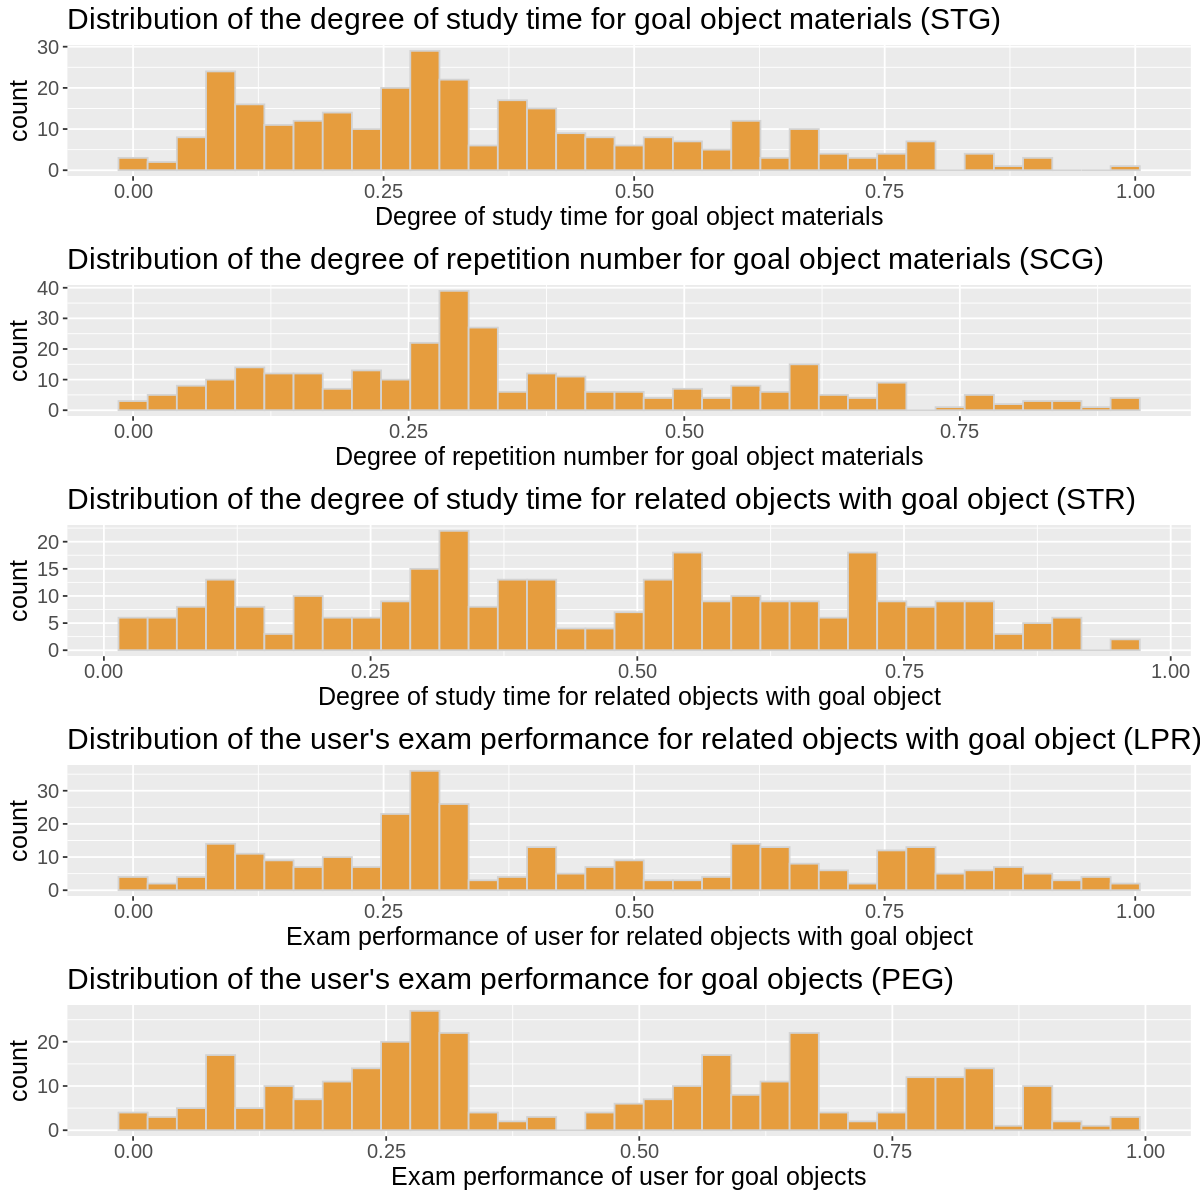

In [32]:
options(repr.plot.width = 10, repr.plot.height = 10)

stg_hist <- ggplot(knowledge_training, aes(x = STG)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the degree of study time for goal object materials (STG)") + 
            xlab("Degree of study time for goal object materials") + 
            theme(text = element_text(size = 15))  

scg_hist <- ggplot(knowledge_training, aes(x = SCG)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the degree of repetition number for goal object materials (SCG)") + 
            xlab("Degree of repetition number for goal object materials") + 
            theme(text = element_text(size = 15))  

str_hist <- ggplot(knowledge_training, aes(x = STR)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the degree of study time for related objects with goal object (STR)") + 
            xlab("Degree of study time for related objects with goal object") + 
            theme(text = element_text(size = 15)) 

lpr_hist <- ggplot(knowledge_training, aes(x = LPR)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the user's exam performance for related objects with goal object (LPR)") + 
            xlab("Exam performance of user for related objects with goal object") + 
            theme(text = element_text(size = 15))  

peg_hist <- ggplot(knowledge_training, aes(x = PEG)) +
            geom_histogram(bins = 35, color = "lightgrey", fill = "#e69d3e") + 
            ggtitle("Distribution of the user's exam performance for goal objects (PEG)") + 
            xlab("Exam performance of user for goal objects") + 
            theme(text = element_text(size = 15))  

plot_grid(stg_hist, scg_hist, str_hist, lpr_hist, peg_hist, nrow = 5)

<span style="color:gray">Figure 1: Distribution of each predictor variable in the training dataset</span>

From the histograms, all the predictors range from a minimum value of 0 to a maximum of 0.99. Most of the histograms are left-skewed, meaning that there aren't many users with values at the upper extreme. Most peaks occur ~0.30.

* **STG** histogram is left-skewed and unimodal with a peak at ~0.10.
* **SCG** histogram is left-skewed and unimodal with a peak at ~0.30.
* **STR** histogram is not obviously skewed but is multimodal with peaks at ~0.30, ~0.52 and ~0.70.
* **LPR** histogram is left-skewed with and unimodal with a peak at ~0.29.
* **PEG** histogram is not obviously skewed but is bimodal with peaks at ~0.29 and ~0.60.

## Data Analysis 

### Cross Validation

During the exploratory data analysis, we split 75% of the data into a training set and the remaining 25% of the data into a testing set. We will begin by performing a 5-fold cross validation using `vfold_cv` to split up the training data. 

In [33]:
knowledge_vfold <- vfold_cv(knowledge_training, v = 5, strata = UNS)

To begin, we will perform forward selection to find a good subset of predictor variables to use. The code for forward selection has been adapted from Timbers et al (2022).

First, we extract the names of the predictor variables and the number of predictors.

In [34]:
names <- knowledge_training %>%
            select(- UNS) %>%
            colnames()
n_total <- length(names)
names

[1] "STG" "SCG" "STR" "LPR" "PEG"

Then, we create a `nearest_neighbors` model specification, with `neighbors = tune()` as we do not yet know the best value of `k`.

In [35]:
knn_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = tune()) %>%
  set_engine("kknn") %>%
  set_mode("classification")

We now create an empty tibble that will store the accuracies from each model run with different set of predictors. We also create an empty vector that will store the selected predictors in each iteration.

In [36]:
# Adapted from Timbers et. al 2022
accuracies <- tibble(size = integer(), 
                     model_string = character(), 
                     accuracy = numeric())
selected_predictors <- c()

Now we will iterate over the number of predictors. In each iteration, we will loop over the predictor names, add a new predcitor to the list of selected predictors, create a model string and recipe with each of the selected predictors. We then tune a model with these predictors and add the highest accuracy from the best `k` to a results dataframe. This process is called **forward selection**.

In [37]:
# Code adapted from Timbers et al. 2022

# for every size from 1 to the total number of predictors
for (i in 1:n_total) {
    # for every predictor still not added yet
    accs <- list()
    models <- list()
    for (j in 1:length(names)) {
        # create a model string for this combination of predictors
        preds_new <- c(selected_predictors, names[[j]])
        model_string <- paste("UNS", "~", paste(preds_new, collapse="+"))
        # create a recipe from the model string
        knowledge_recipe <- recipe(as.formula(model_string), 
                                data = knowledge_training) %>%
                          step_scale(all_predictors()) %>%
                          step_center(all_predictors())

# create a model specification
        # tune the KNN classifier with these predictors, 
        # and collect the accuracy for the best K
        acc <- workflow() %>%
          add_recipe(knowledge_recipe) %>%
          add_model(knn_spec) %>%
          tune_grid(resamples = knowledge_vfold, grid = 10) %>%
          collect_metrics() %>%
          filter(.metric == "accuracy") %>%
          summarize(mx = max(mean))
        acc <- acc$mx %>% unlist()

# add this result to the dataframe
        accs[[j]] <- acc
        models[[j]] <- model_string
    }
    jstar <- which.max(unlist(accs))
    accuracies <- accuracies %>%
      add_row(size = i, 
              model_string = models[[jstar]], 
              accuracy = accs[[jstar]])
    selected_predictors <- c(selected_predictors, names[[jstar]])
    names <- names[-jstar]
}
accuracies

size,model_string,accuracy
<int>,<chr>,<dbl>
1,UNS ~ PEG,0.8487113
2,UNS ~ PEG+LPR,0.9513156
3,UNS ~ PEG+LPR+SCG,0.9474953
4,UNS ~ PEG+LPR+SCG+STG,0.9005246
5,UNS ~ PEG+LPR+SCG+STG+STR,0.8243476


<span style="color:gray">Table 6: Accuracies of models with different subsets of predictor variables</span>

From the above table of accuracies, the model accuracy increases when the variable `LPR` is added compared to the model with `PEG` only. The accuracies then decrease when more predictors are added. The model containing only `LPR` and `PEG` as predictors has the highest accuracy so these are the predictors we will use going forward.

Finally we will perform a **cross validation** to find the optimal number of nearest neighbors.

We create a recipe that specifies the class label (`UNS`) and our chosen predictors (`PEG` and `LPR`), as well as preprocessing steps for the variables.

In [40]:
knowledge_recipe <- recipe(UNS ~ PEG + LPR, 
                        data = knowledge_training) %>%
  step_scale(all_predictors()) %>%
  step_center(all_predictors())

We then create a data frame with a neighbors variable that contains the sequence of values of K to try. The `k_vals` data frame has the neighbors variable containing values from 1 to 100 (stepping by 5) using the `seq()` function.

In [42]:
k_vals <- tibble(neighbors = seq(from = 1, to = 100, by = 5))

Next, we add the recipe and model specification to a `workflow()`, and use the `tune_grid()` function on the train/validation splits to estimate the classifier accuracy for a range of K values.

In [43]:
knn_results <- workflow() %>%
  add_recipe(knowledge_recipe) %>%
  add_model(knn_spec) %>%
  tune_grid(resamples = knowledge_vfold, grid = k_vals) %>%
  collect_metrics()
knn_results

neighbors,.metric,.estimator,mean,n,std_err,.config
<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
1,accuracy,multiclass,0.9402394,5,0.02014531,Model01
1,roc_auc,hand_till,0.9586024,5,0.01287164,Model01
6,accuracy,multiclass,0.9513156,5,0.01427013,Model02
⋮,⋮,⋮,⋮,⋮,⋮,⋮
91,roc_auc,hand_till,0.8785295,5,0.01297593,Model19
96,accuracy,multiclass,0.6275491,5,0.02008941,Model20
96,roc_auc,hand_till,0.8723298,5,0.01441424,Model20


<span style="color:gray">Table 7: Metrics for each classifier with a different number of neighbors parameter</span>

To assess our classifier's accuracy, we use the `metrics()` function to get the statistics about the quality of our model.

In [44]:
accuracies <- knn_results %>%
  filter(.metric == "accuracy")

accuracies

neighbors,.metric,.estimator,mean,n,std_err,.config
<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
1,accuracy,multiclass,0.9402394,5,0.02014531,Model01
6,accuracy,multiclass,0.9513156,5,0.01427013,Model02
11,accuracy,multiclass,0.9409874,5,0.01221071,Model03
⋮,⋮,⋮,⋮,⋮,⋮,⋮
86,accuracy,multiclass,0.6535916,5,0.02278905,Model18
91,accuracy,multiclass,0.6404627,5,0.02542545,Model19
96,accuracy,multiclass,0.6275491,5,0.02008941,Model20


<span style="color:gray">Table 8: Accuracies of each classifier with a different number of neighbors parameter</span>

To decide what number of neighbors is best, we can plot the accuracy versus K. 

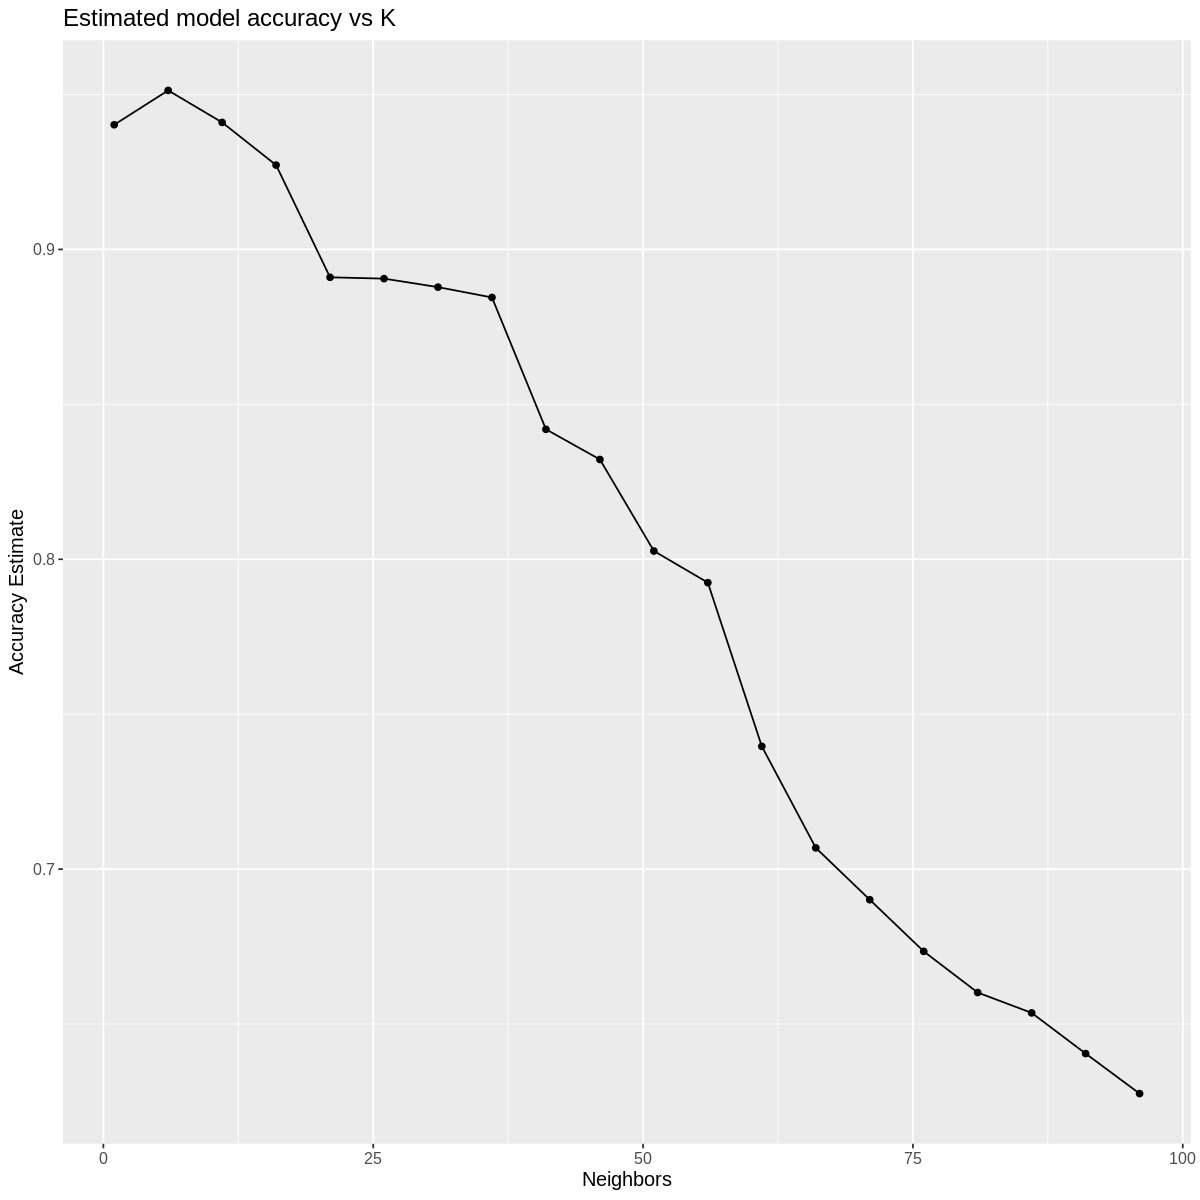

In [46]:
accuracy_vs_k <- ggplot(accuracies, aes(x = neighbors, y = mean)) +
  geom_point() +
  geom_line() +
  labs(x = "Neighbors", y = "Accuracy Estimate") + 
  theme(text = element_text(size = 12)) + 
  ggtitle("Estimated model accuracy vs K")

accuracy_vs_k

<span style="color:gray">Figure 2: The estimated accuracy for each model vs the number of neighbors used in the model</span>

From the plot, it looks like the highest accuracy is between `k` values of 5 and 10. We will zoom in on the above plot by restricting the values of `k` to be between 1 and 20 so we can more clearly find the best value of k.

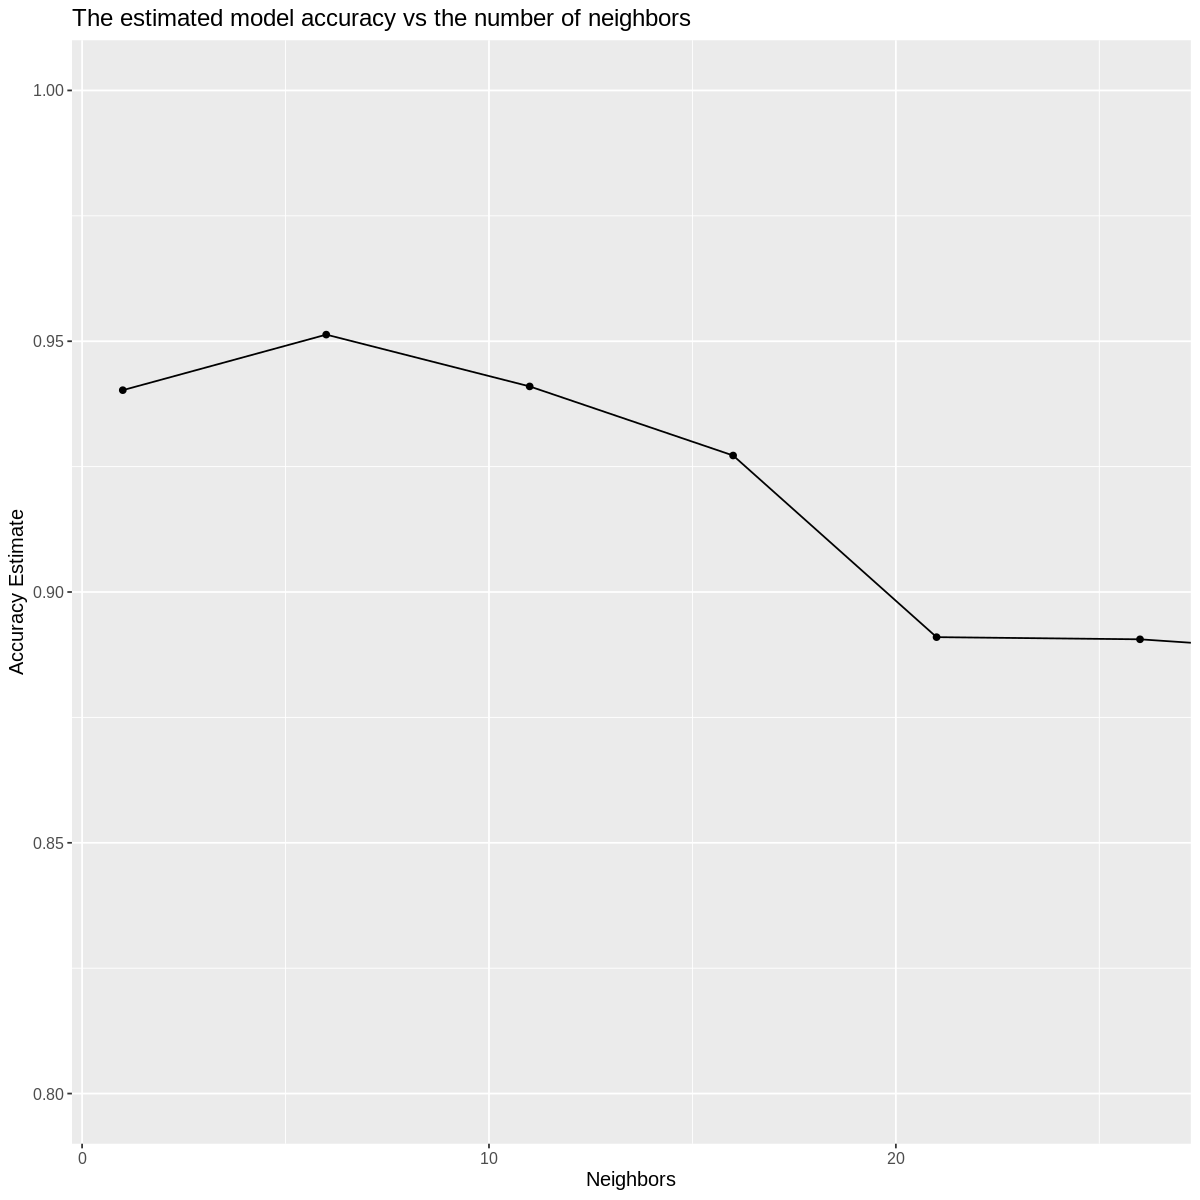

In [65]:
accuracy_vs_k2<- ggplot(accuracies, aes(x = neighbors, y = mean)) +
  geom_point() +
  geom_line() +
  labs(x = "Neighbors", y = "Accuracy Estimate") + 
  coord_cartesian(xlim = c(1, 26), ylim = c(0.8, 1)) +
  theme(text = element_text(size = 12)) + 
  ggtitle("The estimated model accuracy vs the number of neighbors")
accuracy_vs_k2

<span style="color:gray">Figure 3: The estimated accuracy for each model vs the number of neighbors used in the model from 1 to 26</span>

From the plot above, the best value of `k` is 6. Changing `k` by 5 from 6 also does not decrease accuracy by much so we will choose `k = 6` as our nearest neighbors parameter going forward.

Now that we have tuned our model, we will fit the model on the training set with our chosen parameters then predict labels in the test set.

First, we will create a model specification with ``` k = 6 ```. 

In [53]:
knn_spec_tuned <- nearest_neighbor(weight_func = "rectangular", neighbors = 6) %>%
                    set_engine("kknn") %>%
                    set_mode("classification")

Now, we will create a workflow with this specification and fit the data to the training set. For this step, we will re-use the `knowledge_recipe` object since it specifies the predictors we selected (`PEG` and `LPR`).

In [54]:
knowledge_fit_tuned <- workflow() %>%
                        add_recipe(knowledge_recipe) %>%
                        add_model(knn_spec_tuned) %>%
                        fit(data = knowledge_training)

We will now use this classifier to predict labels on the test set.

In [55]:
knowledge_predictions <- predict(knowledge_fit_tuned, knowledge_testing) %>%
                            bind_cols(knowledge_testing)
knowledge_predictions

.pred_class,STG,SCG,STR,LPR,PEG,UNS
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
Very Low,0.00,0.00,0.00,0.00,0.00,Very Low
High,0.08,0.08,0.10,0.24,0.90,High
Middle,0.08,0.08,0.08,0.98,0.24,Low
⋮,⋮,⋮,⋮,⋮,⋮,⋮
Low,0.64,0.59,0.12,0.58,0.24,Low
Low,0.56,0.60,0.77,0.13,0.32,Low
Middle,0.66,0.68,0.81,0.57,0.57,Middle


<span style="color:gray">Table 9: Predicted UNS labels for observations in the test set</span>

To evaluate the classifier's accuracy, we use the `metrics` function using the `UNS` column as the actual labels and the `.pred_class` column as the predicted labels.

In [56]:
knowledge_predictions %>%
    metrics(truth = UNS, estimate = .pred_class) %>%
    filter(.metric == "accuracy")

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.969697


<span style="color:gray">Table 10: The accuracy of the classifier on the testing set</span>

Our classifier has an accuracy of ~97.0%, which means that ~97% of UNS labels were classified correctly on the testing set. It would be useful to see how many predictions were correct at each UNS level. The confusion matrix below displays this information.

In [57]:
confusion_matrix <- knowledge_predictions %>%
                    conf_mat(truth = UNS, estimate = .pred_class)
confusion_matrix

          Truth
Prediction Very Low High Low Middle
  Very Low       12    0   1      0
  High            0   25   0      0
  Low             0    0  30      1
  Middle          0    0   1     29

<span style="color:gray">Table 11: Confusion matrix of the predictions on the test set</span>

It looks like the classifier predicted all `High` UNS lables correctly, but incorrectly classified 1 `Very Low` UNS level as `Low`, 1 `Low` UNS level as `Middle` and 1 `Middle` UNS level as `Low`.

### A Visualization of Our Model's Accuracy

Now let's plot our predictor variables from the testing set, colored by their predicted classes to get a sense of where our model's doing right and which specific points were predicted incorrectly.

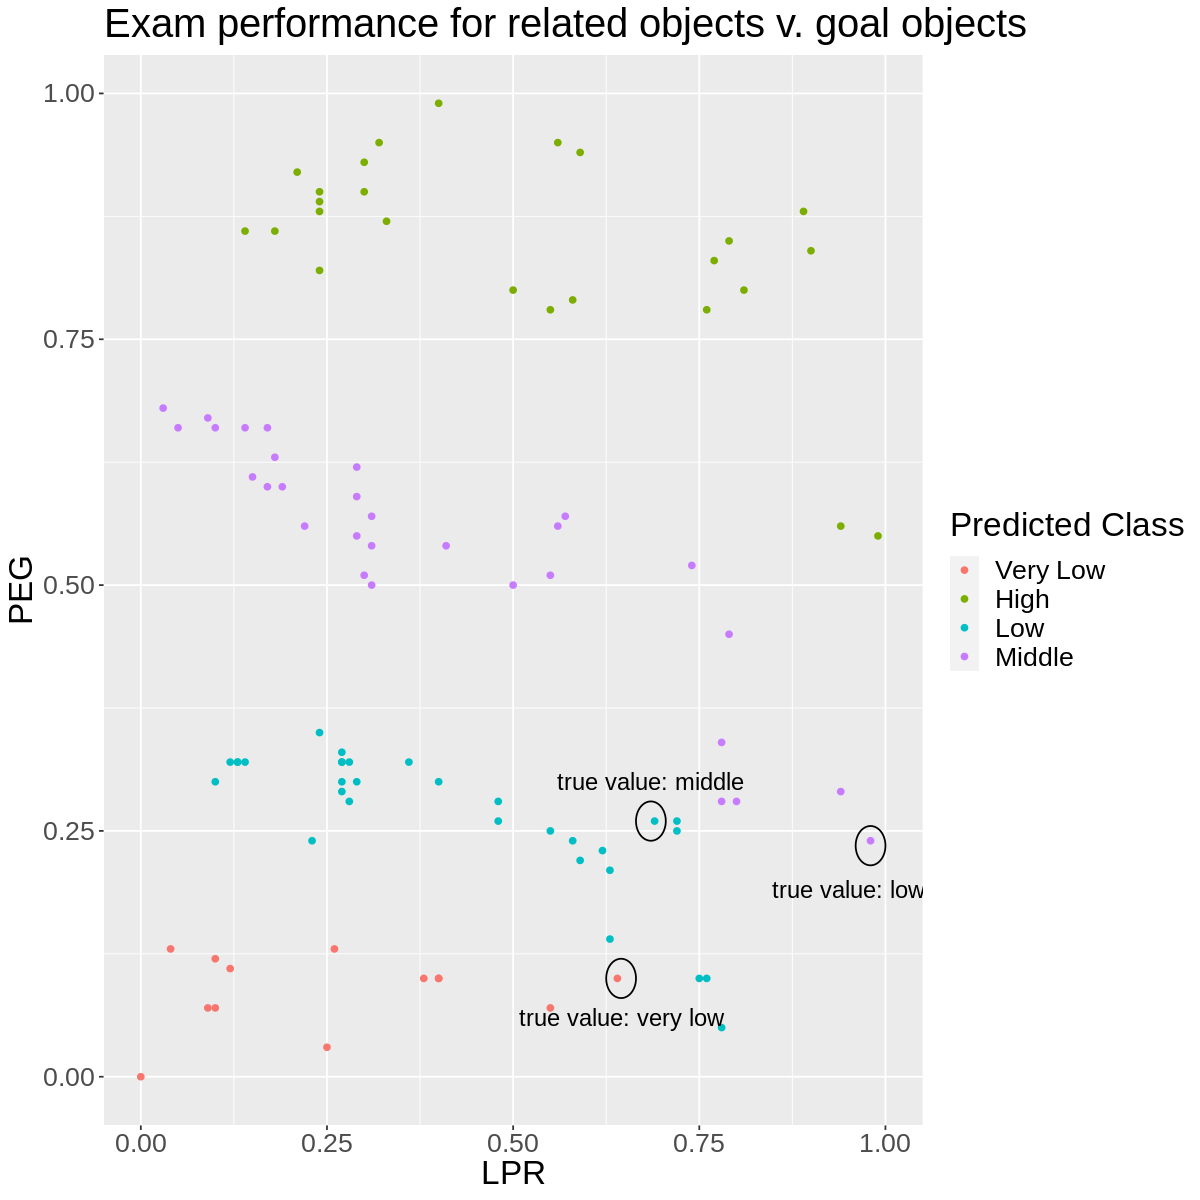

In [119]:
point1 <- c(0.98, 0.235)
point2 <- c(0.685, 0.26)
point3 <- c(0.645, 0.10)

plot_predictions <- knowledge_predictions %>%
    ggplot(aes(x = LPR, y = PEG, color = .pred_class)) + 
        geom_point() +
        labs(x = "LPR", 
             y = "PEG",
            color = "Predicted Class") +
        ggtitle("Exam performance for related objects v. goal objects") +
        theme(text = element_text(size = 20)) +
        annotate("path", 
                 x=point1[1] + 0.02*cos(seq(0,2*pi,length.out=100)),
                 y=point1[2] + 0.02*sin(seq(0,2*pi,length.out=100))) +
        annotate("path", 
                 x=point2[1] + 0.02*cos(seq(0,2*pi,length.out=100)),
                 y=point2[2] + 0.02*sin(seq(0,2*pi,length.out=100))) +
        annotate("path", 
                 x=point3[1] + 0.02*cos(seq(0,2*pi,length.out=100)),
                 y=point3[2] + 0.02*sin(seq(0,2*pi,length.out=100))) +
        annotate("text", x = 0.95, y =  0.19, label = "true value: low", size = 5) +
        annotate("text", x = 0.685, y =  0.3, label = "true value: middle", size = 5) +
        annotate("text", x = 0.645, y =  0.06, label = "true value: very low", size = 5)

plot_predictions 

<span style="color:gray">Figure 4: A scatterplot of PEG v. LPR, colored by the predicted UNS labels </span>

<mark> Placeholder for a brief explanation of the plot <mark> 

## Discussion

## References

H. T. Kahraman, Sagiroglu, S., Colak, I. (2013) 'Developing intuitive knowledge classifier and modeling of users' domain dependent data in web'
*Knowledge Based Systems*, (37)[online]. Available at: https://www.sciencedirect.com/science/article/pii/S0950705112002225

H. T. Kahraman, Sagiroglu, S., Colak, I. (2013) 'User Knowledge Modelling Dataset' [online]. Available at: https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling

Timbers, T, Cambell, T, Lee, M. (2022). *Data Science A First Introduction*[online].
Available at: https://datasciencebook.ca/index.html